# 1-DOF pitch: ONE model for both signals (impulse + doublet)
Same equation as before, but now **one set of wn, xi, mu** must explain both kinds of flight:
- impulse flights (motors off, push, free swing): impulse_1 to impulse_4 train, impulse_5 test
- doublet flights (motors at hover, push one way then the other): doublet_1 to doublet_5 train, doublet_6 test

theta'' = -2 xi wn q - wn^2 (theta - th0) + mu M(t - tau)

Only the rest angle th0 is allowed to differ between the two kinds (th0_imp, th0_dbl), because hovering holds the drone at a different angle.
The question: is one model good enough for both, or do we need the two separate models from before?

## 0. Setup

In [1]:
import numpy as np, pandas as pd, torch, time, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
torch.set_num_threads(4)
D = '../data/1dof/'
FL = pd.read_csv(D + 'flights_1dof.csv').set_index('file')
TAU = 0.02                                                     # delay [s]
TRAIN = [f'impulse_{i}.csv' for i in range(1, 5)] + [f'doublet_{i}.csv' for i in range(1, 6)]
TEST = ['impulse_5.csv', 'doublet_6.csv']
kind = lambda name: name.split('_')[0]                         # 'impulse' or 'doublet'

## 1. Data (same windows as the two separate notebooks)

In [2]:
def load(name):
    r = FL.loc[name]; df = pd.read_csv(D + name)
    if kind(name) == 'impulse':
        end = r.inj_start_s - 0.1 + 6.0                        # push + 6 s of swing
    else:
        after = df[df.t > r.inj_start_s + 0.7]
        end = after.t[after.M.abs() > 0.12].iloc[0] - 0.05     # just before the motor kick-back
    f = df[(df.t >= r.inj_start_s - 0.1) & (df.t < end)].reset_index(drop=True)
    f['t'] = f.t - f.t[0]
    return f
flights = {n: load(n) for n in TRAIN + TEST}
for n in TRAIN + TEST: print(n, f'{flights[n].t.iloc[-1]:.2f} s')

impulse_1.csv 6.00 s
impulse_2.csv 6.00 s
impulse_3.csv 6.00 s
impulse_4.csv 6.00 s
doublet_1.csv 1.46 s
doublet_2.csv 1.46 s
doublet_3.csv 1.45 s
doublet_4.csv 1.45 s
doublet_5.csv 1.46 s
impulse_5.csv 6.00 s
doublet_6.csv 1.46 s


## 2. Physics, written once

In [3]:
def accel(theta, q, M, p):
    return -2 * p['xi'] * p['wn'] * q - p['wn']**2 * (theta - p['th0']) + p['mu'] * M

def run_ivp(p, f):
    t, M = f.t.values, f.M.values
    rhs = lambda tt, z: [z[1], accel(z[0], z[1], np.interp(tt - TAU, t, M), p)]
    return solve_ivp(rhs, (0, t[-1]), [f.theta[0], f.q[0]], t_eval=t, max_step=0.004).y

def vaf(y, yhat):
    return max(1 - np.var(y - yhat) / np.var(y), 0) * 100

def consts_for(p, name):
    # shared wn, xi, mu + the th0 of this flight's kind
    return dict(wn=p['wn'], xi=p['xi'], mu=p['mu'], th0=p['th0_imp' if kind(name) == 'impulse' else 'th0_dbl'])

## 3. Simulation fit, both signals at once
Each flight's error is divided by its own size (std of theta) and by sqrt(length), so the long impulse flights do not drown out the short doublets.

In [4]:
def train_sim_fit_both(names):
    keys = ['wn', 'xi', 'mu', 'th0_imp', 'th0_dbl']
    def residual(v):
        p = dict(zip(keys, v)); out = []
        for n in names:
            f = flights[n]
            e = (run_ivp(consts_for(p, n), f)[0] - f.theta.values) / f.theta.std() / np.sqrt(len(f))
            out.append(e)
        return np.concatenate(out)
    t0 = time.time()
    r = least_squares(residual, [4, 0.2, 100, 0, 0], bounds=([0.5, 0, 0, -0.5, -0.5], [20, 2, 2000, 0.5, 0.5]))
    return dict(p=dict(zip(keys, r.x)), time=time.time() - t0)
sim = train_sim_fit_both(TRAIN)
print({k: round(v, 4) for k, v in sim['p'].items()}, f"({sim['time']:.0f} s)")

{'wn': np.float64(4.0167), 'xi': np.float64(0.2386), 'mu': np.float64(99.4577), 'th0_imp': np.float64(-0.0085), 'th0_dbl': np.float64(-0.1091)} (31 s)


## 4. Inverse PINN, both signals at once
One small network per flight (each network learns that flight's theta(t)), but **all networks share the same wn, xi, mu**. The loss is the average over the 9 flights.

In [5]:
def mlp(n_in, n_out, width=32, depth=3):
    layers, n = [], n_in
    for _ in range(depth):
        layers += [torch.nn.Linear(n, width), torch.nn.Tanh()]; n = width
    return torch.nn.Sequential(*layers, torch.nn.Linear(n, n_out))
col = lambda x: torch.tensor(np.asarray(x), dtype=torch.float32).reshape(-1, 1)
S_TH = 0.3                                                    # theta scale

def train_inverse_pinn_both(names, seed=0, epochs=30000, lr=1e-3, w_data=3000):
    # data
    torch.manual_seed(seed)
    d = {}
    for n in names:
        f = flights[n]
        d[n] = dict(t=col(f.t.values), y=col(f.theta.values), S_T=float(f.t.iloc[-1]),
                    M=col(np.interp(f.t.values - TAU, f.t.values, f.M.values)))
    # networks (one per flight) + shared constants
    nets = {n: mlp(1, 1) for n in names}
    raw = {k: torch.nn.Parameter(torch.tensor(float(v))) for k, v in
           dict(wn=np.log(3.5), xi=np.log(0.1), mu=np.log(100.0), th0_imp=0.0, th0_dbl=0.0).items()}
    consts = lambda: dict(wn=raw['wn'].exp(), xi=raw['xi'].exp(), mu=raw['mu'].exp(), th0_imp=raw['th0_imp'], th0_dbl=raw['th0_dbl'])
    # optimizer
    params = [w for net in nets.values() for w in net.parameters()] + list(raw.values())
    opt = torch.optim.Adam(params, lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=lr / 20)
    # loop
    hist = []
    for e in range(epochs):
        p = consts(); physics = 0; data = 0
        for n in names:
            t = d[n]['t'].clone().requires_grad_(True)
            th = S_TH * nets[n](2 * t / d[n]['S_T'] - 1)
            q = torch.autograd.grad(th, t, torch.ones_like(th), create_graph=True)[0]
            a = torch.autograd.grad(q, t, torch.ones_like(q), create_graph=True)[0]
            physics = physics + (((a - accel(th, q, d[n]['M'], consts_for(p, n))) / S_TH) ** 2).mean() / len(names)
            data = data + (((th - d[n]['y']) / S_TH) ** 2).mean() / len(names)
        loss = physics + w_data * data
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if e % 500 == 0 or e == epochs - 1:
            hist.append((e, physics.item(), data.item(), p['wn'].item(), p['xi'].item(), p['mu'].item()))
    p = {k: float(v.detach()) for k, v in consts().items()}
    return dict(p=p, history=pd.DataFrame(hist, columns=['epoch', 'physics', 'data', 'wn', 'xi', 'mu']))

t0 = time.time(); pinn = train_inverse_pinn_both(TRAIN); pinn['time'] = time.time() - t0
print({k: round(v, 4) for k, v in pinn['p'].items()}, f"({pinn['time']:.0f} s)")

{'wn': 3.9953, 'xi': 0.0529, 'mu': 97.2687, 'th0_imp': -0.0042, 'th0_dbl': -0.0959} (911 s)


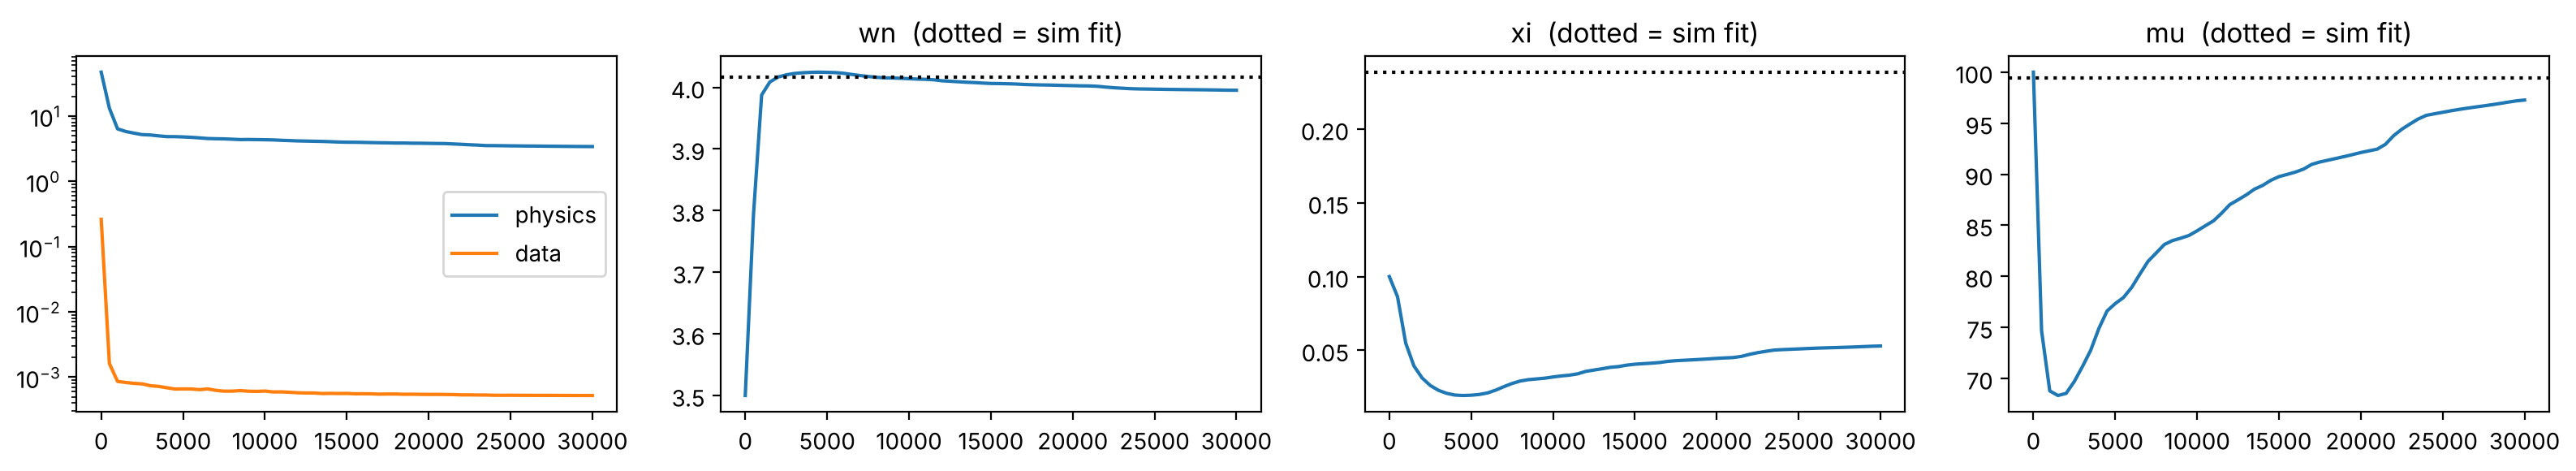

In [6]:
h = pinn['history']
fig, ax = plt.subplots(1, 4, figsize=(16, 3))
ax[0].semilogy(h.epoch, h.physics, label='physics'); ax[0].semilogy(h.epoch, h.data, label='data'); ax[0].legend()
for i, k in enumerate(['wn', 'xi', 'mu']):
    ax[i + 1].plot(h.epoch, h[k]); ax[i + 1].axhline(sim['p'][k], color='k', ls=':'); ax[i + 1].set_title(k + '  (dotted = sim fit)')
plt.tight_layout(); plt.show()

## 5. Results: one model vs the two separate models, on both test flights

In [7]:
sep_imp = pd.read_csv('../results/batch1_2_constants.csv', index_col=0)
sep_dbl = pd.read_csv('../results/batch1_2_doublet_constants.csv', index_col=0)
def sep(tab, colname, th0):
    c = tab[colname]; return dict(wn=float(c['wn [rad/s]']), xi=float(c['xi [-]']), mu=float(c['mu [rad/s^2]']), th0=th0)
rows = {}
for label, p in [('Sim fit, ONE model', sim['p']), ('Inverse PINN, ONE model', pinn['p'])]:
    rows[label] = [p['wn'], p['xi'], p['mu']] + [vaf(flights[n].theta.values, run_ivp(consts_for(p, n), flights[n])[0]) for n in TEST]
# separate models: impulse constants on impulse_5, doublet constants on doublet_6.
# th0 of the separate doublet models (from the doublet notebook): sim fit -0.1665, PINN mean of 5 flights -0.1506
TH0_DBL = {'Sim fit (4 flights)': -0.1665, 'Inverse PINN (mean of 4)': -0.1506}
for label, colname in [('Sim fit, TWO models', 'Sim fit (4 flights)'), ('Inverse PINN, TWO models', 'Inverse PINN (mean of 4)')]:
    pi = sep(sep_imp, colname, 0.0)
    pd_ = sep(sep_dbl, colname.replace('4', '5'), TH0_DBL[colname])
    rows[label] = ['two sets', '', ''] + [vaf(flights['impulse_5.csv'].theta.values, run_ivp(pi, flights['impulse_5.csv'])[0]),
                                       vaf(flights['doublet_6.csv'].theta.values, run_ivp(pd_, flights['doublet_6.csv'])[0])]
table = pd.DataFrame(rows, index=['wn [rad/s]', 'xi [-]', 'mu [rad/s^2]', 'test VAF impulse_5 [%]', 'test VAF doublet_6 [%]']).T
table.to_csv('../results/batch1_2c_both_signals.csv')
table

,wn [rad/s],xi [-],mu [rad/s^2],test VAF impulse_5 [%],test VAF doublet_6 [%]
"Sim fit, ONE model",4.016691,0.238563,99.457726,90.098089,67.651338
"Inverse PINN, ONE model",3.995275,0.052931,97.268677,0.0,84.792474
"Sim fit, TWO models",two sets,,,96.98805,98.802845
"Inverse PINN, TWO models",two sets,,,94.692296,99.019451


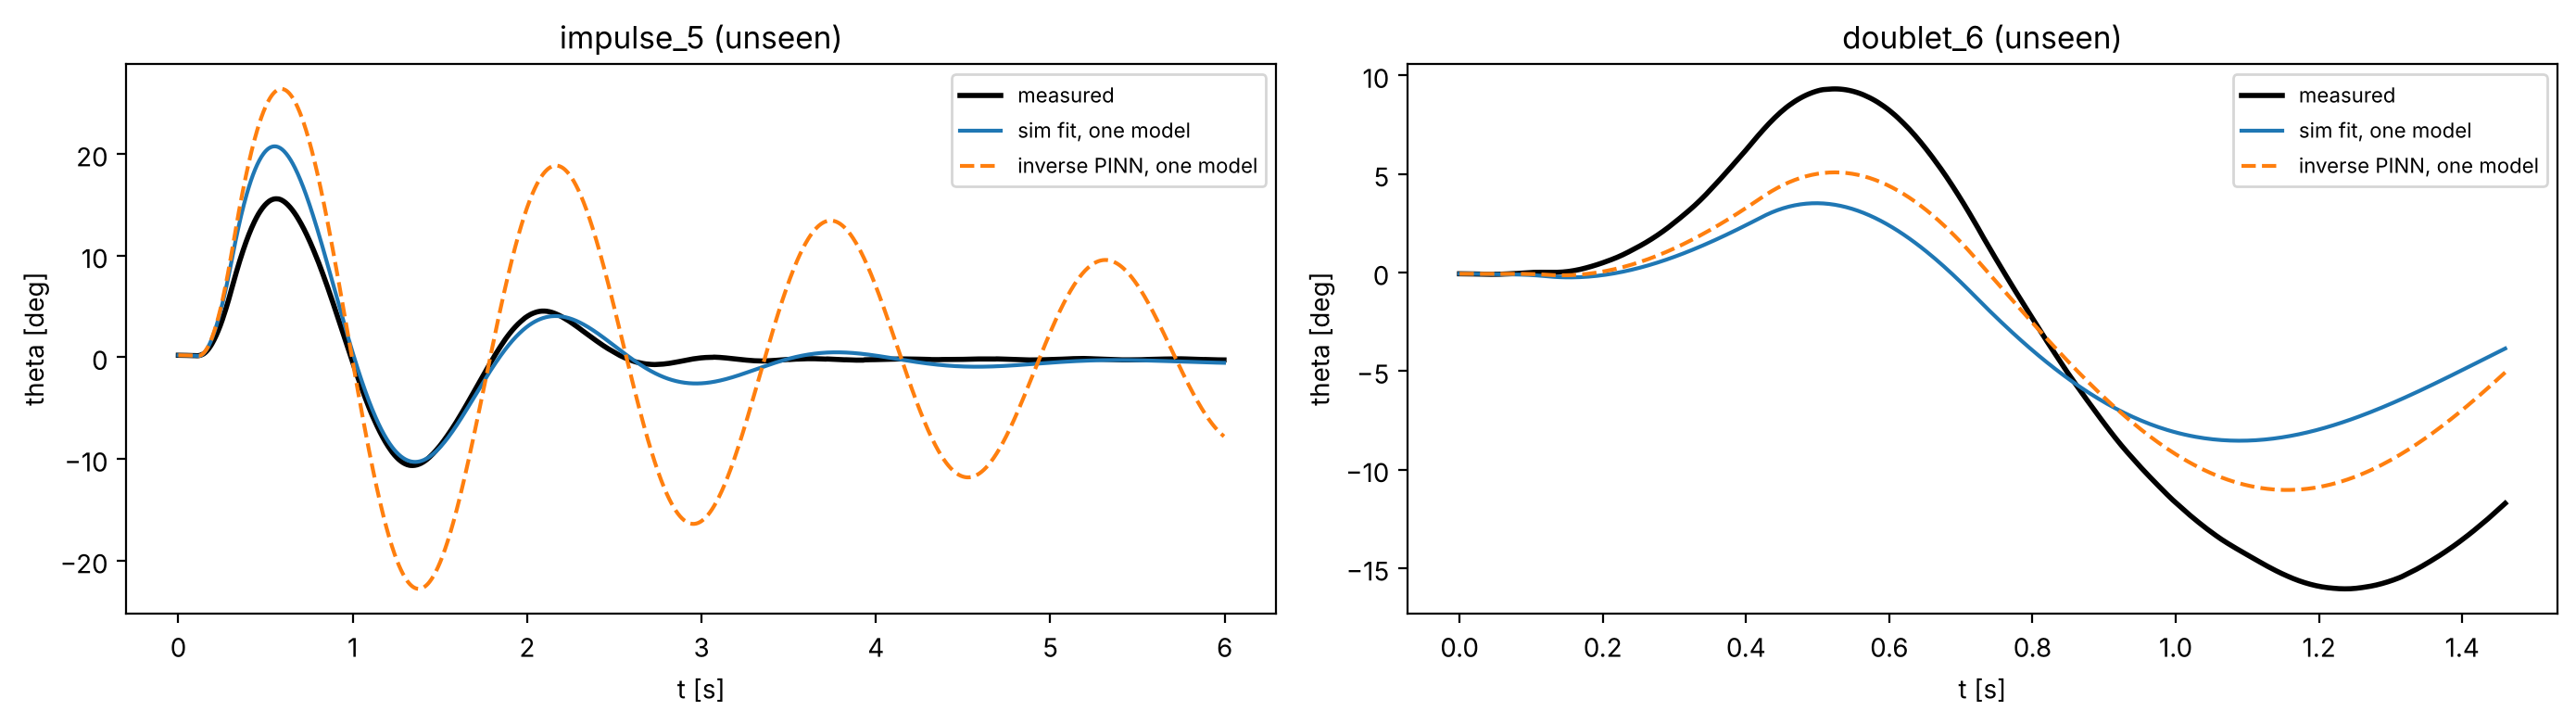

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, n in zip(ax, TEST):
    f = flights[n]
    a.plot(f.t, np.degrees(f.theta), 'k', lw=2, label='measured')
    a.plot(f.t, np.degrees(run_ivp(consts_for(sim['p'], n), f)[0]), label='sim fit, one model')
    a.plot(f.t, np.degrees(run_ivp(consts_for(pinn['p'], n), f)[0]), '--', label='inverse PINN, one model')
    a.set(title=n.replace('.csv', '') + ' (unseen)', xlabel='t [s]', ylabel='theta [deg]'); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig('../figures/batch1_2c_both_signals.png', dpi=120, bbox_inches='tight'); plt.show()

## 6. What this shows
- If the ONE-model VAF is close to the TWO-model VAF on both test flights, one model is enough.
- If it drops a lot on one of them, motors-off and hover really are different systems: the thrust changes the pitch dynamics, and the simple equation needs a thrust term (or separate constants) to cover both.